**HARTH Data Loading and Inspection**

![Stage 01 horizontal workflow diagram](../images/01_workflow.svg)

**Human Movement Intelligence | Presented by: Reza Saadatyar (2026)**

**Objective:** Reuse our common `load_data`, `inspect_data` and `plot_signal` functions with a different biomedical movement dataset.

**Dataset:** Human Activity Recognition Trondheim, authors' official GitHub **v2.0** release. The first demonstration downloads only subject `S023.csv`. UCI has an older **v1.2** release of 22 participants; do not mix the versions. No model training is performed.

**01. Imports and environment**

Reuse the same Python functions as the BoneNet notebook. The HARTH-specific adapter is the only new data interpreter.

In [1]:
# ==================== 01. Imports and Environment ====================

# 1. Import the Python standard library used for portable paths.
import sys
from pathlib import Path
# 2. Import plotting and tabular display tools.
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

# 3. Find the repository root without a machine-specific path.
root = Path.cwd().resolve()
while not (root / "code/python/src/core/data_loading.py").is_file():
    if root == root.parent:
        raise RuntimeError("Open this notebook from inside human-movement-intelligence.")
    root = root.parent

sys.path.insert(0, str(root / "code/python/src"))
sys.path.insert(0, str(root / "studies/wearable_activity_recognition/src"))

# 4. Reuse the existing generic source readers and inspectors.
from core.data_loading import load_data
from core.data_inspection import inspect_data, plot_signal
# 5. Import the validated HARTH-specific source adapter.
from harth_data import (
    ACTIVITY_NAMES, SENSOR_COLUMNS,
    ensure_harth_sample, load_harth_subject,
)

# 6. Confirm source utilities and repository path are available.
print("Repository:", root)
print("Reusable loading and visualisation functions: ready")

Repository: D:\human-movement-intelligence
Reusable loading and visualisation functions: ready


**02. Download only the selected public participant**

The `S023.csv` source is cached in ignored `data/raw/harth_v2/`. It comes from an exact pinned revision of the authors' repository.

In [2]:
# ==================== 02. Retrieve Original HARTH Source ====================

# 1. Use the repository's ignored cache for the chosen source participant.
data_dir = root / "data" / "raw" / "harth_v2"
# 2. Download only when the exact public source is not cached.
csv_path = ensure_harth_sample(data_dir, subject="S023")
# 3. Report the selected source path.
print("Source file:", csv_path)

Downloaded 12,061,722 bytes to D:\human-movement-intelligence\data\raw\harth_v2\S023.csv
Source file: D:\human-movement-intelligence\data\raw\harth_v2\S023.csv


**03. General file reading and structural inspection**

First call the same general `load_data()` function as in the BoneNet notebook. It does not encode HARTH-specific scientific meaning.

In [3]:
# ==================== 03. Inspect Raw Source Table ====================

# 1. Read original source columns using the common reader.
raw_table = load_data(csv_path)
# 2. Inspect data shape and missingness without changing samples.
raw_report = inspect_data(raw_table, name="HARTH raw participant CSV")
# 3. Report observed source column names.
print("Raw columns:", list(raw_table.columns))


===== HARTH raw participant CSV =====
Rows: 137646 | Columns: 8
Missing values: 0
Columns: timestamp, back_x, back_y, back_z, thigh_x, thigh_y, thigh_z, label
              timestamp    back_x    back_y    back_z   thigh_x   thigh_y   thigh_z  label
2019-01-12 00:00:00.000 -1.108887  0.057861 -0.076904 -1.396973 -0.327148 -0.141846      6
2019-01-12 00:00:00.020 -1.054932  0.073486 -0.113770 -1.363281 -0.386475 -0.321533      6
2019-01-12 00:00:00.040 -0.911377 -0.007568 -0.160156 -1.080078 -0.096680 -0.354492      6
2019-01-12 00:00:00.060 -0.865234 -0.062500 -0.176025 -1.012939  0.163574 -0.229736      6
2019-01-12 00:00:00.080 -0.992920 -0.026123 -0.178467 -0.989014  0.199951 -0.088379      6
Raw columns: ['timestamp', 'back_x', 'back_y', 'back_z', 'thigh_x', 'thigh_y', 'thigh_z', 'label']


**04. Validate this source with the HARTH adapter**

Validate timestamp parsing, six acceleration columns in **g**, and activity codes. This remains one continuous recording from one person.

In [4]:
# ==================== 04. Validate HARTH Signal Schema ====================

# 1. Validate the HARTH schema and the six original sensor channels.
data, channel_names = load_harth_subject(csv_path)
# 2. Inspect the validated source recording.
summary = inspect_data(data, name="HARTH validated participant")
# 3. Report subject, channels and source sampling information.
print("Subject identifier:", csv_path.stem)
print("Accelerometer channels:", channel_names)
print("Sampling rate (source documentation): 50 Hz")

HARTH subject S023: 137,646 rows, 6 sensors

===== HARTH validated participant =====
Rows: 137646 | Columns: 8
Missing values: 0
Columns: timestamp, back_x, back_y, back_z, thigh_x, thigh_y, thigh_z, label
              timestamp    back_x    back_y    back_z   thigh_x   thigh_y   thigh_z  label
2019-01-12 00:00:00.000 -1.108887  0.057861 -0.076904 -1.396973 -0.327148 -0.141846      6
2019-01-12 00:00:00.020 -1.054932  0.073486 -0.113770 -1.363281 -0.386475 -0.321533      6
2019-01-12 00:00:00.040 -0.911377 -0.007568 -0.160156 -1.080078 -0.096680 -0.354492      6
2019-01-12 00:00:00.060 -0.865234 -0.062500 -0.176025 -1.012939  0.163574 -0.229736      6
2019-01-12 00:00:00.080 -0.992920 -0.026123 -0.178467 -0.989014  0.199951 -0.088379      6
Subject identifier: S023
Accelerometer channels: ['back_x', 'back_y', 'back_z', 'thigh_x', 'thigh_y', 'thigh_z']
Sampling rate (source documentation): 50 Hz


**05. Explore the true label distribution**

Activity codes are published by the authors. Counts in this cell are calculated from the **actual** `S023.csv` data.

,label,activity,samples
0,1,Walking,70601
1,2,Running,22391
2,3,Shuffling,2071
3,4,Stairs ascending,3194
4,5,Stairs descending,2291
5,6,Standing,7455
6,7,Sitting,13059
7,8,Lying,16584


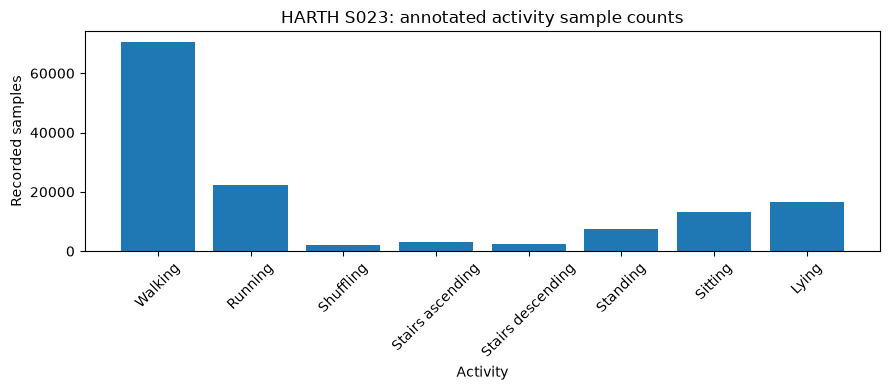

In [5]:
# ==================== 05. Summarise Activity Distribution ====================

# 1. Count the actual labels present in the selected recording.
activity_counts = data["label"].value_counts().sort_index()
# 2. Build a source-code-to-activity summary.
activity_table = pd.DataFrame({
    "label": activity_counts.index,
    "activity": [ACTIVITY_NAMES[int(value)] for value in activity_counts.index],
    "samples": activity_counts.to_numpy(),
})
# 3. Display label support before plotting.
display(activity_table)

# 4. Visualise the source activity counts with labelled axes.
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(activity_table["activity"], activity_table["samples"])
ax.set(title="HARTH S023: annotated activity sample counts",
       xlabel="Activity", ylabel="Recorded samples")
ax.tick_params(axis="x", labelrotation=45)
fig.tight_layout()
plt.show()

**06. Plot original movement signals**

These are observed sensor values for the first 250 samples; this is not a machine-learning prediction. The units are **g**, as documented by HARTH.

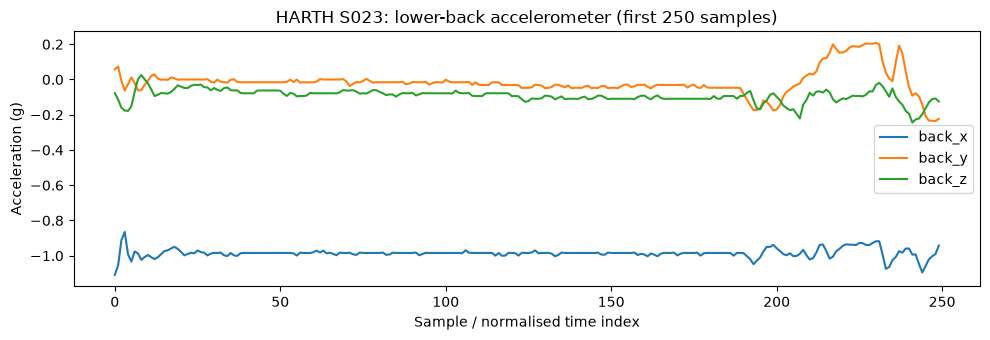

In [6]:
# ==================== 06. Plot Observed Motion Signals ====================

# 1. Limit the visual preview without altering the raw recording.
n_points = min(250, len(data))
# 2. Extract original back-accelerometer channels for display.
signal = data.loc[:n_points - 1, channel_names[:3]].to_numpy().T
# 3. Reuse the shared signal plotting function.
fig = plot_signal(
    signal,
    title="HARTH S023: lower-back accelerometer (first 250 samples)",
    channel_names=channel_names[:3],
)
fig.axes[0].set_ylabel("Acceleration (g)")
plt.show()

**07. Data-quality gate and takeaways**

This shows successful reuse across source formats. A single subject cannot support unseen-subject generalisation experiments. Windowing, participant-disjoint splits and model training belong in later notebooks.

In [7]:
# ==================== 07. Source Data Quality Gate ====================

# 1. Verify channel count, required columns and finite source values.
assert len(channel_names) == 6
assert set(["timestamp", "label"]).issubset(data.columns)
assert data[channel_names].notna().all().all()
assert not data.empty
# 2. Calculate the observed source sampling interval.
time_delta = data["timestamp"].diff().dt.total_seconds().dropna()
# 3. Summarise scientific checks and explicitly exclude model training.
print("\n" + "=" * 72)
print("STAGE 01 | SOURCE DATA QUALITY GATE")
print("=" * 72)
print("Number of rows:", len(data))
print("Median observed time interval (s):", time_delta.median())
print("Observed activity codes:", sorted(data["label"].unique().tolist()))
print("Generic reader and inspector reused: YES")
print("Model training performed: NO")
print("=" * 72)


Number of rows: 137646
Median observed time interval (s): 0.02
Observed activity codes: [1, 2, 3, 4, 5, 6, 7, 8]
Generic reader and inspector reused: YES
Model training performed: NO
